<a href="https://colab.research.google.com/github/ddev3r/Machine-learning/blob/main/%D0%A1%D1%82%D0%B0%D1%80%D0%BE%D0%B2%D0%BE%D0%B9%D1%82%D0%BE%D0%B2_%D0%9B%D0%A0_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завдання №1

№1 Завантажити датасет Ірис. Роздрукувати перші 5 рядочків.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Перші 5 рядків датасету Ірис:")
display(df.head())

Перші 5 рядків датасету Ірис:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


№2 Методом ліктя і методом силуєтів визначити оптимальну кількість кластерів.

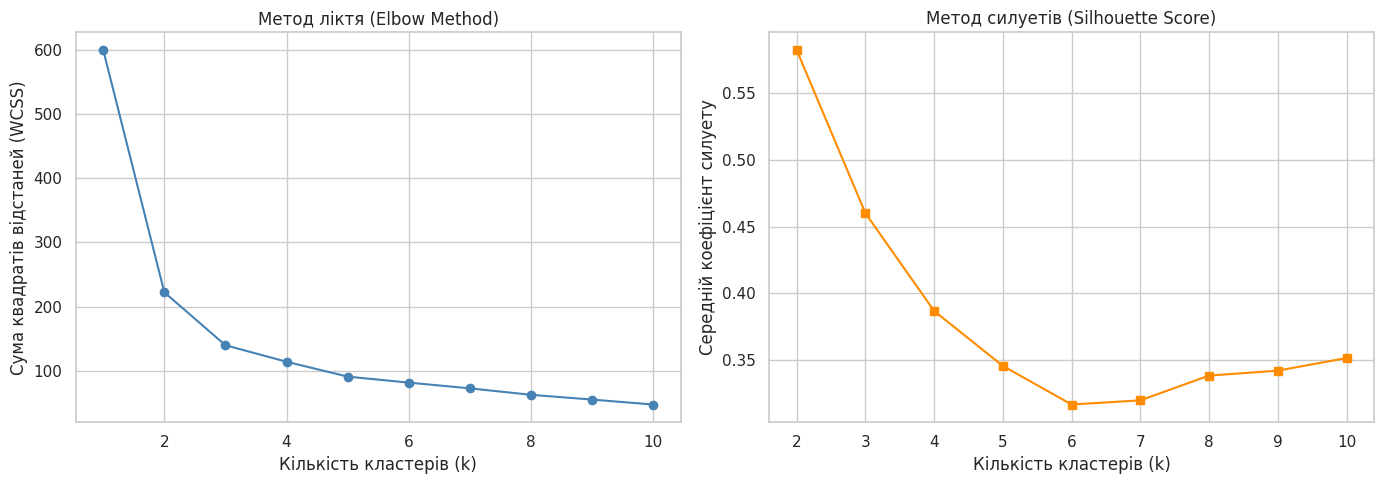

In [ ]:
sc = StandardScaler()
X_sc = sc.fit_transform(df)

wcss = []
sil = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sc)
    wcss.append(km.inertia_)
    if k >= 2:
        sil.append(silhouette_score(X_sc, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(K_range, wcss, marker="o", color="steelblue")
ax[0].set_title("Метод ліктя (Elbow Method)")
ax[0].set_xlabel("Кількість кластерів (k)")
ax[0].set_ylabel("Сума квадратів відстаней (WCSS)")

ax[1].plot(range(2, 11), sil, marker="s", color="darkorange")
ax[1].set_title("Метод силуетів (Silhouette Score)")
ax[1].set_xlabel("Кількість кластерів (k)")
ax[1].set_ylabel("Середній коефіцієнт силуету")

plt.tight_layout()
plt.show()

№3 Візуалізувати кластери.

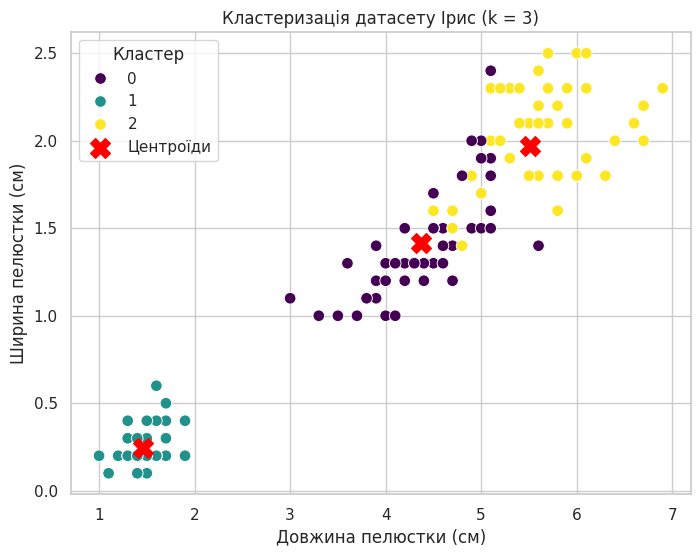

In [ ]:
km_best = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = km_best.fit_predict(X_sc)

centers = sc.inverse_transform(km_best.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="cluster",
    palette="viridis",
    s=70
)
plt.scatter(
    centers[:, 2],
    centers[:, 3],
    c="red",
    s=200,
    marker="X",
    label="Центроїди"
)
plt.title("Кластеризація датасету Ірис (k = 3)")
plt.xlabel("Довжина пелюстки (см)")
plt.ylabel("Ширина пелюстки (см)")
plt.legend(title="Кластер")
plt.show()

Висновок: У ході виконання першого завдання було завантажено датасет Iris, який містить чотири числові характеристики квітів. На графіку методу ліктя чіткий згин спостерігається при k = 3, після чого зменшення внутрішньокластерної суми квадратів відстаней сповільнюється. Метод силуетів показує максимум при k = 2 (оскільки два види ірисів частково перекриваються за ознаками) та стабільно високе значення при k = 3, що підтверджує оптимальний поділ вибірки на три кластери.

Завдання №2

№1 Реалізувати попередній аналіз даних:
Роздрукувати перші 5 рядків.
Вивести розмір датасета, типи даних.
Перевірити на пропущені значення. При наявності замінити на середнє за
стовпцем.
Перевірити на дублікати. Якщо є – видалити. Вивести описову статистику.

In [10]:
from google.colab import files

uploaded = files.upload()
fname = next(iter(uploaded))
df2 = pd.read_csv(fname)

# 1. Перші 5 рядків
print("Перші 5 рядків датасету:")
display(df2.head())

# 2. Розмір датасету та типи даних
print(f"\nРозмір датасету: {df2.shape}")
print("\nТипи даних:\n", df2.dtypes)

# 3. Перевірка на пропущені значення та заміна на середнє за стовпцем
print("\nПропущені значення до обробки:\n", df2.isnull().sum())
df2 = df2.fillna(df2.mean(numeric_only=True))

# 4. Перевірка та видалення дублікатів
dups = df2.duplicated().sum()
print(f"\nКількість дублікатів: {dups}")
if dups > 0:
    df2 = df2.drop_duplicates()
    print(f"Новий розмір після видалення дублікатів: {df2.shape}")

# 5. Описова статистика
print("\nОписова статистика:")
display(df2.describe())

Saving house_price_regression_dataset.csv to house_price_regression_dataset (1).csv
Перші 5 рядків датасету:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06



Розмір датасету: (1000, 8)

Типи даних:
 Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

Пропущені значення до обробки:
 Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Кількість дублікатів: 0

Описова статистика:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


№2 Визначити, яку задачу розв’язуємо (регресія чи класифікація). Побудувати 3
моделі на вибір для визначення оцінки. Підібрати оптимальні параметри.
Оцінити моделі.

In [12]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Цільова змінна House_Price є неперервною -> розв'язуємо задачу РЕГРЕСІЇ
X2 = df2.drop(columns=["House_Price"])
y2 = df2["House_Price"]

X_tr, X_te, y_tr, y_te = train_test_split(X2, y2, test_size=0.2, random_state=123)

grids = {
    "Регресія Ріджа (Ridge)": (
        Pipeline([("sc", StandardScaler()), ("reg", Ridge())]),
        {"reg__alpha": [0.01, 0.1, 1.0, 10.0]}
    ),
    "Випадковий ліс (Random Forest)": (
        RandomForestRegressor(random_state=123),
        {"n_estimators": [50, 100, 200], "max_depth": [5, 10, None]}
    ),
    "Градієнтний бустинг": (
        GradientBoostingRegressor(random_state=123),
        {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 4]}
    )
}

res = []
for name, (model, params) in grids.items():
    gs = GridSearchCV(model, params, cv=5, scoring="r2", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    pred = gs.best_estimator_.predict(X_te)

    res.append({
        "Модель": name,
        "Найкращі параметри": str(gs.best_params_),
        "R2": r2_score(y_te, pred),
        "RMSE ($)": np.sqrt(mean_squared_error(y_te, pred)),
        "MAE ($)": mean_absolute_error(y_te, pred)
    })

res_df = pd.DataFrame(res).sort_values(by="R2", ascending=False)
display(res_df)

,Модель,Найкращі параметри,R2,RMSE ($),MAE ($)
0,Регресія Ріджа (Ridge),{'reg__alpha': 0.1},0.998451,10188.751180,8079.345334
2,Градієнтний бустинг,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.996572,15157.926170,12095.214935
1,Випадковий ліс (Random Forest),"{'max_depth': None, 'n_estimators': 200}",0.992606,22262.607389,17793.433448


№3 Визначити методом ліктя і силуєтів оптимальну кількість кластерів.
Візуалізувати кластери.

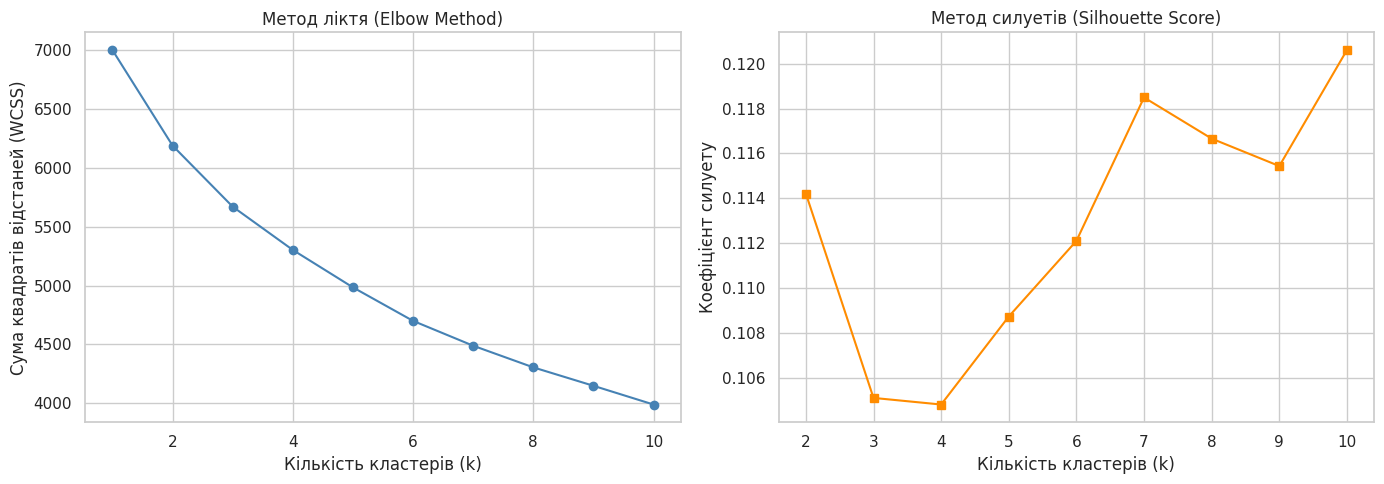

Оптимальна кількість кластерів за силуетом: k = 10


In [16]:
sc2 = StandardScaler()
X2_sc = sc2.fit_transform(X2)

wcss2 = []
sil2 = []

for k in K_range:
    km2 = KMeans(n_clusters=k, random_state=123, n_init=10)
    km2.fit(X2_sc)
    wcss2.append(km2.inertia_)
    if k >= 2:
        sil2.append(silhouette_score(X2_sc, km2.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(K_range, wcss2, marker="o", color="steelblue")
ax[0].set_title("Метод ліктя (Elbow Method)")
ax[0].set_xlabel("Кількість кластерів (k)")
ax[0].set_ylabel("Сума квадратів відстаней (WCSS)")

ax[1].plot(range(2, 11), sil2, marker="s", color="darkorange")
ax[1].set_title("Метод силуетів (Silhouette Score)")
ax[1].set_xlabel("Кількість кластерів (k)")
ax[1].set_ylabel("Коефіцієнт силуету")

plt.tight_layout()
plt.show()

best_k = list(range(2, 11))[int(np.argmax(sil2))]
print(f"Оптимальна кількість кластерів за силуетом: k = {best_k}")

Візуалізувати кластери.

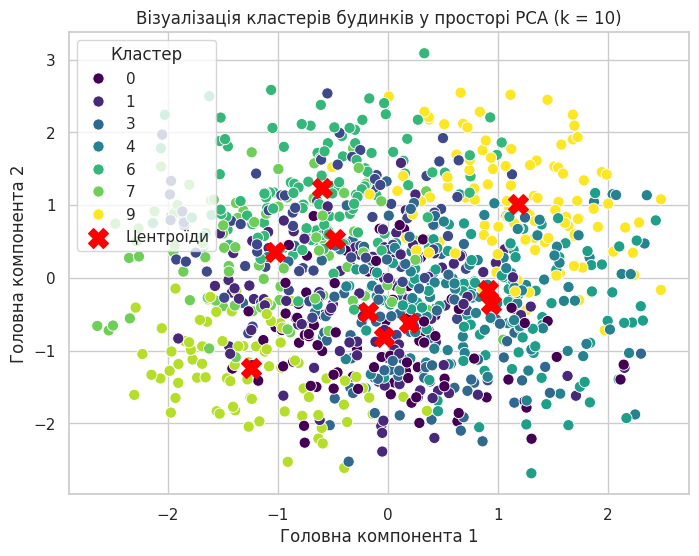

In [17]:
from sklearn.decomposition import PCA

km2_best = KMeans(n_clusters=best_k, random_state=123, n_init=10)
clusters2 = km2_best.fit_predict(X2_sc)

# Зниження розмірності до 2 компонент для візуалізації на площині
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X2_sc)
centers_pca = pca.transform(km2_best.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters2, palette="viridis", s=65)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="red", s=200, marker="X", label="Центроїди")
plt.title(f"Візуалізація кластерів будинків у просторі PCA (k = {best_k})")
plt.xlabel("Головна компонента 1")
plt.ylabel("Головна компонента 2")
plt.legend(title="Кластер")
plt.show()

Висновок: У ході виконання другого завдання було проаналізовано датасет house_price_regression_dataset.csv, розв'язано задачу регресії, де після підбору параметрів через GridSearchCV найкращу точність показала регресія Ріджа $R^2$ = 0,9984, RMSE = 10,071,95, випередивши  градієнтний бустинг $R^2$ = 0,9969 та випадковий ліс $R^2$ = 0,9940$. Подальша кластеризація з визначенням кількості кластерів за методом ліктя й силуету k = 9 та візуалізацією у просторі PCA підтвердила рівномірний розподіл характеристик будинків без чітко відокремлених природних груп.